# Multinomial logistic regression for crash severity

Predict Slight, Serious, or Fatal on the same matched 2025 STATS19 crashes used in the Random Forest experiment. The main run uses seven input groups, with annual average daily flow (AADF) as a road-level traffic-volume proxy. A second run uses the same crashes and model settings with AADF removed.

Logistic regression provides a linear baseline. Standardize numeric columns so the regularization treats speed, cyclical time, and AADF on comparable scales.

Keep `matched_crashes.csv.gz` beside this notebook. Use the package versions listed in the project README. The notebook needs pandas, NumPy, scikit-learn, Matplotlib, and Jupyter.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

if "get_ipython" in globals():
    get_ipython().run_line_magic("matplotlib", "inline")

LABELS = ["Slight", "Serious", "Fatal"]
TARGET = "severity"
AADF = "aadf_motor_vehicles_per_day"
CATEGORICAL = ["road_type", "weather_conditions", "road_surface_conditions"]
BASE_NUMERIC = ["speed_limit", "time_sin", "time_cos"]
data = pd.read_csv("matched_crashes.csv.gz", dtype={"collision_index": str},
                   float_precision="round_trip")
assert data["collision_index"].is_unique
assert set(data["split"]) == {"train", "validation", "test"}
assert set(data[TARGET]) == set(LABELS)
assert data[AADF].notna().all()

train = data.loc[data["split"] == "train"]
validation = data.loc[data["split"] == "validation"]
development = data.loc[data["split"] != "test"]
test = data.loc[data["split"] == "test"]
base_features = data.columns.drop(["collision_index", "split", TARGET, AADF]).tolist()
with_aadf = base_features + [AADF]
print(pd.crosstab(data["split"], data[TARGET]).reindex(columns=LABELS).to_string())

severity    Slight  Serious  Fatal
split                             
test          3057      808     49
train         9472     2773    126
validation    2378      698     36


## Preprocess within the model pipeline

One-hot encode road type, weather, and road-surface codes. Give missing categories their own code. Impute numeric values with training medians. Keep the binary vehicle flags as supplied in the prepared data. Each fit learns preprocessing from its own training rows.

In [2]:
def make_pipeline(features, complexity, class_weight):
    numeric = BASE_NUMERIC + ([AADF] if AADF in features else [])
    vehicles = [column for column in features if column not in CATEGORICAL + numeric]
    categories = Pipeline([
        ("missing", SimpleImputer(strategy="constant", fill_value=-1)),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    numbers = Pipeline([
        ("missing", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    preprocessing = ColumnTransformer([
        ("categorical", categories, CATEGORICAL),
        ("numeric", numbers, numeric),
        ("vehicle_flags", "passthrough", vehicles),
    ])
    classifier = LogisticRegression(C=complexity, class_weight=class_weight, solver='lbfgs', max_iter=2000)
    return Pipeline([("preprocess", preprocessing), ("model", classifier)])

## Choose settings on validation crashes

The search varies model complexity and training class weights. It also tries multiplying the Serious and Fatal scores before choosing the predicted class. This can change the trade-off between catching rare crashes and raising false alarms. Select the combination with the highest validation macro F1, breaking ties by accuracy. The search uses the seven-input pipeline because that is the main experiment. Freeze the selected settings and decision rule for both final runs.

In [3]:
def choose_score_weights(probabilities, actual, classes):
    # Keep the Slight multiplier at 1 while searching the other two.
    y = pd.Categorical(actual, categories=classes).codes
    counts = np.bincount(y, minlength=len(classes))
    serious, fatal = [classes.index(label) for label in ("Serious", "Fatal")]
    multipliers = (0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0)
    best = None
    for serious_weight in multipliers:
        for fatal_weight in multipliers:
            weights = np.ones(len(classes))
            weights[serious], weights[fatal] = serious_weight, fatal_weight
            prediction = (probabilities * weights).argmax(axis=1)
            predicted_counts = np.bincount(prediction, minlength=len(classes))
            correct_counts = np.bincount(y[y == prediction], minlength=len(classes))
            macro_f1 = (2 * correct_counts / (counts + predicted_counts)).mean()
            accuracy = correct_counts.sum() / len(y)
            score = (float(macro_f1), float(accuracy))
            if best is None or score > best[0]:
                best = score, dict(zip(classes, weights.tolist()))
    return best


moderate = {"Slight": 1.0, "Serious": 1.5, "Fatal": 4.0}
training_weights = (("unweighted", None), ("moderate", moderate), ("balanced", "balanced"))

In [4]:
complexity_values = (0.1, 1.0, 10.0)

candidates = []
with threadpool_limits(limits=2):
    for complexity in complexity_values:
        for weight_name, class_weight in training_weights:
            candidate = make_pipeline(with_aadf, complexity, class_weight)
            candidate.fit(train[with_aadf], train[TARGET])
            probabilities = candidate.predict_proba(validation[with_aadf])
            score, decision_weights = choose_score_weights(
                probabilities, validation[TARGET], candidate.classes_.tolist()
            )
            candidates.append({
                "complexity": complexity,
                "weight_name": weight_name,
                "class_weight": class_weight,
                "decision_weights": decision_weights,
                "validation_macro_f1": score[0],
                "validation_accuracy": score[1],
            })
selected = max(candidates, key=lambda row: (
    row["validation_macro_f1"], row["validation_accuracy"]
))
print(pd.DataFrame(candidates)[
    ["complexity", "weight_name", "validation_macro_f1", "validation_accuracy"]
].sort_values("validation_macro_f1", ascending=False).round(4).to_string(index=False))
print("\nSelected settings")
print(json.dumps(selected, indent=2))

 complexity weight_name  validation_macro_f1  validation_accuracy
       10.0  unweighted               0.4143               0.6523
        1.0    moderate               0.4118               0.6462
       10.0    moderate               0.4091               0.6494
        0.1    moderate               0.4066               0.6427
        0.1    balanced               0.4016               0.6989
        1.0    balanced               0.4005               0.6915
       10.0    balanced               0.3996               0.6906
        0.1  unweighted               0.3933               0.6568
        1.0  unweighted               0.3912               0.6536

Selected settings
{
  "complexity": 10.0,
  "weight_name": "unweighted",
  "class_weight": null,
  "decision_weights": {
    "Fatal": 8.0,
    "Serious": 3.0,
    "Slight": 1.0
  },
  "validation_macro_f1": 0.41432364545769323,
  "validation_accuracy": 0.6523136246786633
}


## Refit and evaluate on the shared test split

Fit each final pipeline on train plus validation. Compare accuracy, macro F1, fatal precision and recall, and fatal average precision. Average precision uses the raw fatal scores and summarizes the precision–recall curve. The confusion matrices report counts so a change of one or two fatal cases stays visible.

In [5]:
def test_model(features):
    model = make_pipeline(features, selected["complexity"], selected["class_weight"])
    with threadpool_limits(limits=2):
        model.fit(development[features], development[TARGET])
        probabilities = model.predict_proba(test[features])
    classes = model.classes_.tolist()
    weights = [selected["decision_weights"][label] for label in classes]
    predicted = model.classes_[(probabilities * weights).argmax(axis=1)]
    actual = test[TARGET]
    per_class = classification_report(actual, predicted, labels=LABELS,
                                      output_dict=True, zero_division=0)
    matrix = confusion_matrix(actual, predicted, labels=LABELS)
    return model, {
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(actual, predicted, labels=LABELS, average="macro"),
        "fatal_precision": per_class["Fatal"]["precision"],
        "fatal_recall": per_class["Fatal"]["recall"],
        "fatal_average_precision": average_precision_score(
            actual.eq("Fatal"), probabilities[:, classes.index("Fatal")]
        ),
        "fatal_detected": int(matrix[2, 2]),
        "fatal_predictions": int(matrix[:, 2].sum()),
        "fatal_test_cases": int(matrix[2].sum()),
        "confusion_matrix": matrix.tolist(),
        "per_class": {label: per_class[label] for label in LABELS},
    }


model_without_aadf, without_aadf = test_model(base_features)
model_with_aadf, with_aadf_result = test_model(with_aadf)
results = {"Without AADF": without_aadf, "With AADF": with_aadf_result}
columns = ["accuracy", "macro_f1", "fatal_precision", "fatal_recall",
           "fatal_average_precision", "fatal_detected", "fatal_predictions"]
print(pd.DataFrame(results).T[columns].to_string(
    float_format=lambda value: f"{value:.4f}"
))

             accuracy macro_f1 fatal_precision fatal_recall fatal_average_precision fatal_detected fatal_predictions
Without AADF   0.6875   0.4419          0.2188       0.1429                  0.0698              7                32
With AADF      0.6702   0.4351          0.2258       0.1429                  0.0712              7                31


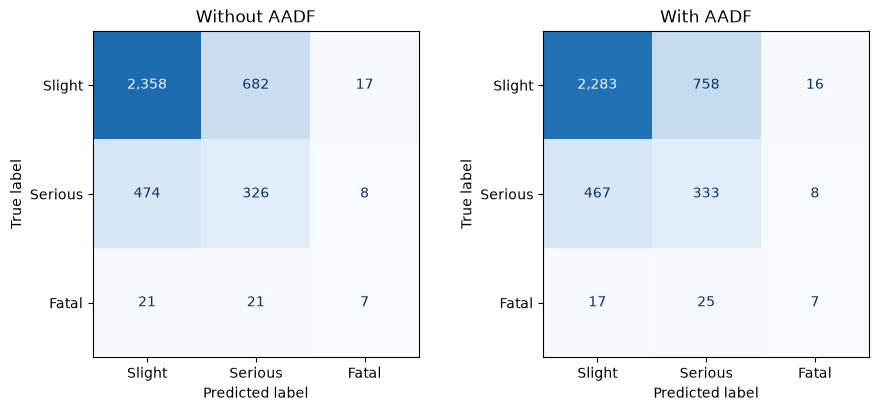

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for ax, (name, scores) in zip(axes, results.items()):
    matrix = np.asarray(scores["confusion_matrix"])
    ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",d",
        im_kw={"vmin": 0, "vmax": int((test[TARGET] == "Slight").sum())},
    )
    ax.set_title(name)
plt.show()